# Fast Fashion Network: supply chain model and hub attack (Model 2)

Student Name : Radiah, Flora

This notebook builds the network from our dataset (`fast_fashion_dataset/`), adds the supply-and-demand market from the README, and runs Simulation 1 (removing the biggest hub vs. random failure).

## Setup: libraries, styling and shared settings

In [1]:
import os, zipfile
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import brentq      # finds the price where supply = demand

# Configure global visualization styling (same style as our Vilar notebook)
plt.rcParams.update({"figure.dpi": 110,
                     "axes.spines.top": False,
                     "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10})

# Reproducibility: random failure picks countries at random, so we fix the seed
rng = np.random.default_rng(42)

# The dataset is shipped as a zip in the repo: unzip it once if the folder is missing
DATA = "fast_fashion_dataset"
if not os.path.isdir(DATA):
    with zipfile.ZipFile(DATA + ".zip") as z:
        z.extractall(".")

---
# 1. Data

One table per node type. Every value comes from `producers.csv` / `consumers.csv`; the sources are in `parameters.csv` and the README.

In [2]:
prod = pd.read_csv(f"{DATA}/producers.csv").set_index("iso3")
cons = pd.read_csv(f"{DATA}/consumers.csv").set_index("iso3")
edges = pd.read_csv(f"{DATA}/edges_estimated.csv")
events = pd.read_csv(f"{DATA}/events.csv")

# Order producers from biggest to smallest exporter, so every plot uses the same order
prod = prod.sort_values("exports_2024_usd_bn", ascending=False)
PRODUCERS = list(prod.index)
CONSUMERS = list(cons.index)

# One fixed colour per country, used in every figure
COLORS = dict(zip(PRODUCERS, [c for k, c in enumerate(plt.cm.tab10.colors) if k != 7]))   # skip grey
CONS_COLOR = "#4d4d4d"   # markets: dark grey

print("PRODUCTION COUNTRIES")
display(prod[["country", "exports_2024_usd_bn", "world_share_2024_pct", "wage_usd_month",
              "safety_score_0_10", "env_regulation_E_0_10", "capacity_usd_bn"]])
print("\nCONSUMER MARKETS")
display(cons)

# Closed system check: total production must equal total demand (balance equation)
print(f"\nTotal production: ${prod.exports_2024_usd_bn.sum():.1f}bn"
      f"   |   Total demand: ${cons.demand_model_usd_bn.sum():.1f}bn")

PRODUCTION COUNTRIES


,country,exports_2024_usd_bn,world_share_2024_pct,wage_usd_month,safety_score_0_10,env_regulation_E_0_10,capacity_usd_bn
iso3,,,,,,,
CHN,China,165.24,29.64,482,2,3.39,198.29
BGD,Bangladesh,38.48,6.90,102,2,2.35,46.18
VNM,Vietnam,33.94,6.09,163,4,2.38,40.73
TUR,Turkey,17.91,3.21,655,2,3.43,21.49
IND,India,16.36,2.94,124,2,2.25,19.63
KHM,Cambodia,9.89,1.77,208,2,3.12,11.87
PAK,Pakistan,9.28,1.66,135,2,2.90,11.14
IDN,Indonesia,8.73,1.57,172,2,2.62,10.48



CONSUMER MARKETS


,market,imports_2023_usd_bn,world_import_share_2023_pct,share_of_5_markets,demand_model_usd_bn
iso3,,,,,
EU,European Union,203,35.8,0.5767,172.91
USA,United States,89,15.7,0.2528,75.81
JPN,Japan,26,4.5,0.0739,22.15
GBR,United Kingdom,21,3.8,0.0597,17.89
KOR,South Korea,13,2.3,0.0369,11.07



Total production: $299.8bn   |   Total demand: $299.8bn


Total production equals total demand. The 5 markets also buy from the EU and others, so their demand is scaled to their share of what our 8 producers export (README, parameter 10).

---
# 2. The network

Edges are producer → consumer, weighted by export value. Until the BACI data is downloaded, the weights come from **proportional allocation**, $w_{ij} = P_i \cdot C_j / Q$ (each producer splits its output in the same proportions as the markets' demand). This is also our null model.

In [3]:
def build_network(production, demand):
    """Bipartite directed network: production[i] and demand[j] in USD bn.
    Edge weight = proportional allocation P_i * C_j / Q."""
    Q = sum(demand.values())
    G = nx.DiGraph()
    for i, P in production.items():
        G.add_node(i, node_type="production", production=P)
    for j, D in demand.items():
        G.add_node(j, node_type="consumption", demand=D)
    for i, P in production.items():
        for j, D in demand.items():
            G.add_edge(i, j, weight=P * D / Q)
    return G

P0 = prod.exports_2024_usd_bn.to_dict()      # baseline production (2024 exports)
D0 = cons.demand_model_usd_bn.to_dict()      # baseline demand
G0 = build_network(P0, D0)
print("Nodes:", G0.number_of_nodes(), " Edges:", G0.number_of_edges())

Nodes: 13  Edges: 40


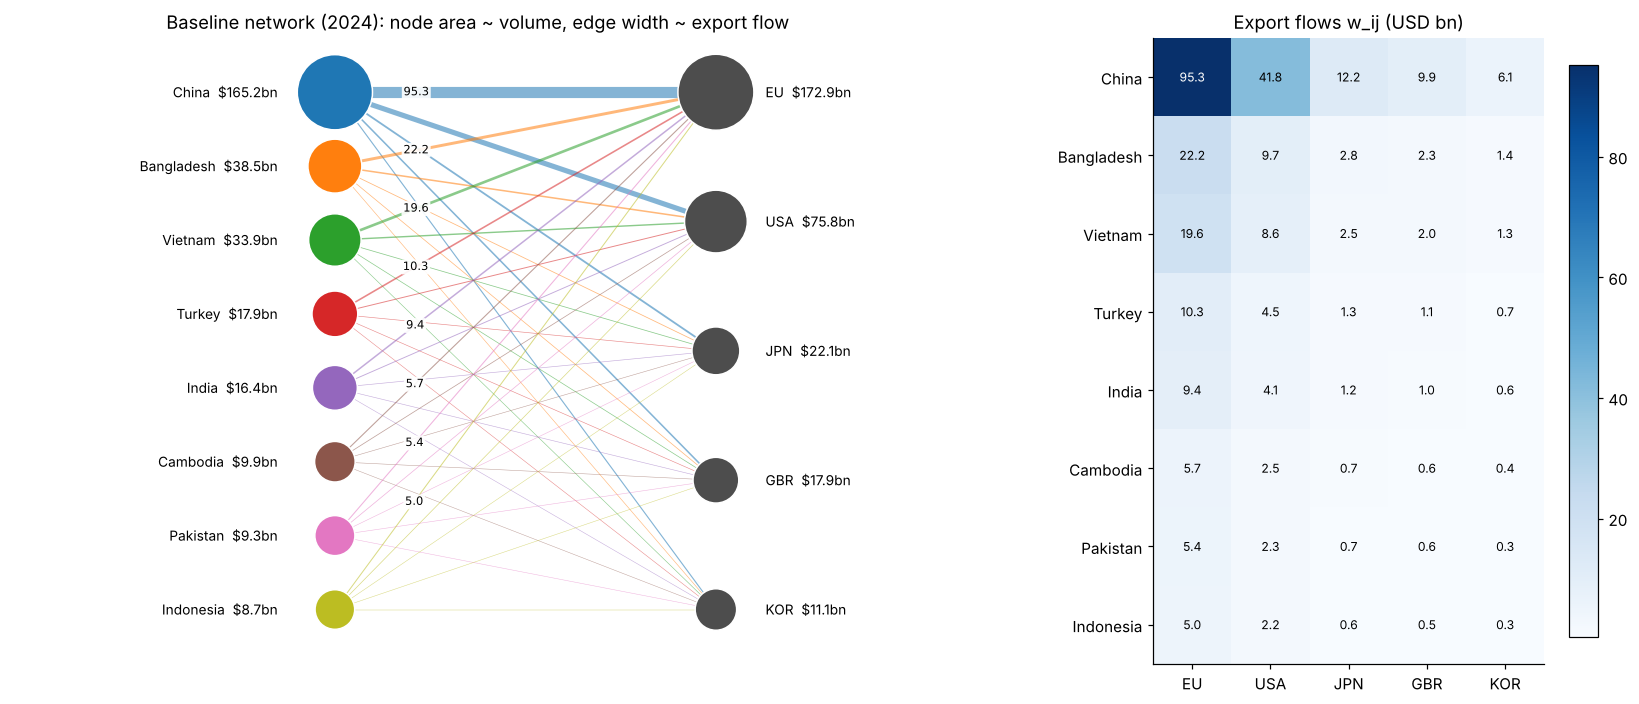

In [4]:
def draw_network(G, title, ax, label_top=8, ref=None):
    """Two-column layout: producers left (sorted by size), markets right.
    Node area ~ volume, edge width ~ weight, each producer's biggest flow gets a label
    (labelling all 40 edges makes the plot unreadable; the heatmap shows every value).
    ref = baseline network: nodes that lost production are drawn with a dashed ring."""
    prods = [n for n in PRODUCERS if n in G]
    conss = [n for n in CONSUMERS if n in G]
    pos = {n: (0, -k) for k, n in enumerate(prods)}
    span = len(prods) - 1
    pos.update({n: (1, -k * span / (len(conss) - 1)) for k, n in enumerate(conss)})

    w = np.array([d["weight"] for _, _, d in G.edges(data=True)])
    wmax = max(w.max(), 1e-9)
    # edges: colour of the producer, width scaled to the largest flow
    for (u, v, d) in G.edges(data=True):
        nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], ax=ax,
                               width=0.3 + 7 * d["weight"] / wmax,
                               edge_color=[COLORS[u]], alpha=0.55, arrows=False)

    size = lambda x: 150 + 2500 * np.sqrt(x / 200)       # sqrt so China does not hide the rest
    nx.draw_networkx_nodes(G, pos, nodelist=prods, ax=ax,
                           node_size=[size(G.nodes[n]["production"]) for n in prods],
                           node_color=[COLORS[n] for n in prods], edgecolors="white")
    nx.draw_networkx_nodes(G, pos, nodelist=conss, ax=ax, node_color=CONS_COLOR,
                           node_size=[size(G.nodes[n]["demand"]) for n in conss], edgecolors="white")
    if ref is not None:   # mark producers that lost output
        hit = [n for n in prods if G.nodes[n]["production"] < ref.nodes[n]["production"] - 1e-6]
        nx.draw_networkx_nodes(G, pos, nodelist=hit, ax=ax, node_color="none", node_size=2600,
                               edgecolors="black", linewidths=1.2).set_linestyle("--")

    # node labels outside the nodes: name + volume
    for n in prods:
        x, y = pos[n]
        ax.text(x - 0.15, y, f"{prod.loc[n,'country']}  ${G.nodes[n]['production']:.1f}bn",
                ha="right", va="center", fontsize=9)
    for n in conss:
        x, y = pos[n]
        ax.text(x + 0.13, y, f"{n}  ${G.nodes[n]['demand']:.1f}bn", ha="left", va="center", fontsize=9)

    # one label per producer: its largest flow, written near the producer end of the edge
    # (edges fan out there, so labels never stack; the heatmap shows every value)
    top = [max(G.out_edges(n, data=True), key=lambda e: e[2]["weight"]) for n in prods][:label_top]
    nx.draw_networkx_edge_labels(G, pos, ax=ax, label_pos=0.2, font_size=7.5, rotate=False,
        edge_labels={(u, v): f"{d['weight']:.1f}" for u, v, d in top},
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))
    ax.set_xlim(-0.85, 1.6); ax.set_title(title); ax.axis("off")

def draw_heatmap(G, ax, title="Export flows w_ij (USD bn)"):
    """Every edge weight as a matrix: rows = producers, columns = markets."""
    W = np.array([[G[i][j]["weight"] for j in CONSUMERS] for i in PRODUCERS])
    im = ax.imshow(W, cmap="Blues")
    ax.set_xticks(range(len(CONSUMERS)), CONSUMERS)
    ax.set_yticks(range(len(PRODUCERS)), [prod.loc[i, "country"] for i in PRODUCERS])
    for r in range(W.shape[0]):
        for c in range(W.shape[1]):
            ax.text(c, r, f"{W[r,c]:.1f}", ha="center", va="center", fontsize=8,
                    color="white" if W[r, c] > W.max() / 2 else "black")
    ax.grid(False); ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
draw_network(G0, "Baseline network (2024): node area ~ volume, edge width ~ export flow", ax[0])
draw_heatmap(G0, ax[1])
plt.tight_layout(); plt.show()

China is by far the biggest hub: its edge to the EU alone is larger than all of Bangladesh's exports. The EU is the biggest market, so every producer's thickest edge goes there. With proportional allocation every row of the heatmap has the same shape; real BACI flows will show which links are stronger than size alone explains.

---
# 3. Network measures

**Strength** = total production (weighted out-degree). **Eigenvector centrality** is computed on the undirected network: our network has no loops (goods only flow producer → consumer), so on the directed version the largest eigenvalue would be 0 (Week 4).

,strength_usd_bn,eigenvector,share_of_production
CHN,165.24,0.666,0.551
BGD,38.48,0.155,0.128
VNM,33.94,0.137,0.113
TUR,17.91,0.072,0.060
IND,16.36,0.066,0.055
KHM,9.89,0.040,0.033
PAK,9.28,0.037,0.031
IDN,8.73,0.035,0.029


Targeted hub (highest eigenvector centrality): China


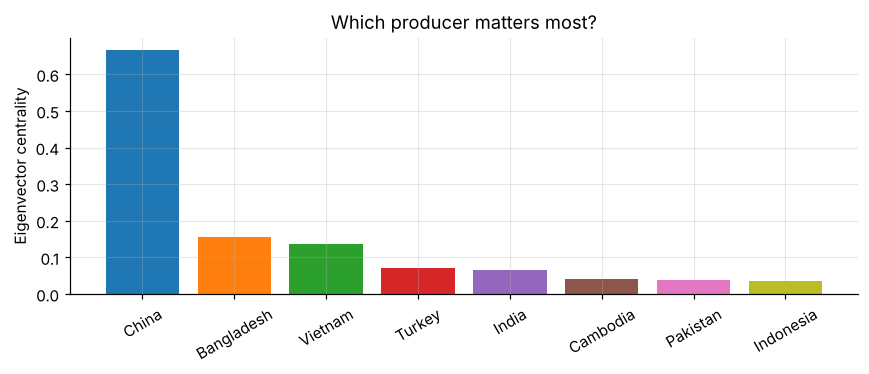

In [5]:
def hub_measures(G):
    strength = dict(G.out_degree(weight="weight"))
    eig = nx.eigenvector_centrality_numpy(G.to_undirected(), weight="weight")
    return pd.DataFrame({"strength_usd_bn": {n: strength[n] for n in PRODUCERS},
                         "eigenvector": {n: eig[n] for n in PRODUCERS}}).loc[PRODUCERS]

M0 = hub_measures(G0)
M0["share_of_production"] = M0.strength_usd_bn / M0.strength_usd_bn.sum()
display(M0.round(3))

TARGET = M0.eigenvector.idxmax()
print("Targeted hub (highest eigenvector centrality):", prod.loc[TARGET, "country"])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar([prod.loc[i, "country"] for i in PRODUCERS], M0.eigenvector, color=[COLORS[i] for i in PRODUCERS])
ax.set_ylabel("Eigenvector centrality"); ax.set_title("Which producer matters most?")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

---
# 4. The market (macro perspective)

- **Supply:** $S_i(p) = \min(K_i,\; s_i\,(p - c_i))$, more output when the price is higher, up to capacity $K_i$.
- **Demand:** $D_j(p) = A_j - B_j\,p$, markets buy less when the price is higher.
- **Equilibrium:** one world price $p^*$ where $\sum_i S_i(p^*) = \sum_j D_j(p^*)$.

All market parameters sit in one dictionary, so a sweep only changes the dictionary (no edits inside the functions).

In [6]:
# MARKET PARAMETERS (README section 6, items 7-10). Change values here only.
PARAMS = dict(p0=1.0,        # baseline world price (normalized)
              lam=0.5,       # labour share: unit cost c_i = lam * W_i / W_max
              eps=0.5,       # demand price elasticity: B_j = eps * C_j / p0
              spare=0.2)     # spare capacity: K_i = P_i * (1 + spare)

def calibrate(par):
    """Return numpy arrays so the market clears at p0 with the 2024 values."""
    P = prod.exports_2024_usd_bn.values                     # production per producer
    W = prod.wage_usd_month.values                          # wage per producer
    c = par["lam"] * W / W.max()                            # unit cost, always below p0
    s = P / (par["p0"] - c)                                 # supply slope: S_i(p0) = P_i
    K = P * (1 + par["spare"])                              # capacity
    C = cons.demand_model_usd_bn.values
    B = par["eps"] * C / par["p0"]                          # demand slope
    A = C + B * par["p0"]                                   # demand intercept: D_j(p0) = C_j
    return dict(P=P, c=c, s=s, K=K, A=A, B=B)

def supply(p, m, K=None):
    """Vectorized supply of every producer at price p (capacity can be overridden by a shock)."""
    K = m["K"] if K is None else K
    return np.minimum(K, np.maximum(0.0, m["s"] * (p - m["c"])))

def demand(p, m):
    return np.maximum(0.0, m["A"] - m["B"] * p)

def equilibrium(m, K=None):
    """World price where total supply = total demand (excess demand crosses zero)."""
    excess = lambda p: demand(p, m).sum() - supply(p, m, K).sum()
    p_star = brentq(excess, 1e-6, 10 * PARAMS["p0"])
    return p_star, supply(p_star, m, K), demand(p_star, m)

MKT = calibrate(PARAMS)
p_star, S_star, D_star = equilibrium(MKT)
print(f"Baseline equilibrium: p* = {p_star:.3f},  Q* = ${S_star.sum():.1f}bn  (should be 1.000 and 299.8)")

Baseline equilibrium: p* = 1.000,  Q* = $299.8bn  (should be 1.000 and 299.8)


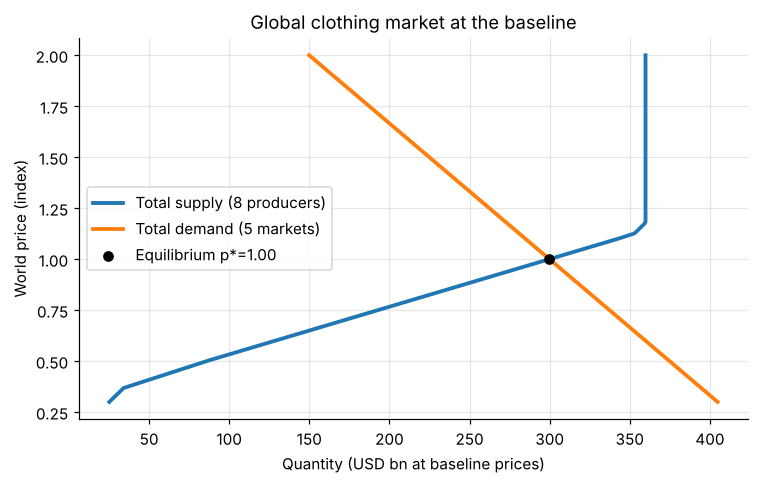

In [7]:
# Supply and demand curves at the baseline: where they cross is today's market
p_grid = np.linspace(0.3, 2.0, 300)
tot_S = [supply(p, MKT).sum() for p in p_grid]
tot_D = [demand(p, MKT).sum() for p in p_grid]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(tot_S, p_grid, lw=2.5, label="Total supply (8 producers)")
ax.plot(tot_D, p_grid, lw=2.5, label="Total demand (5 markets)")
ax.scatter([S_star.sum()], [p_star], color="black", zorder=5, label=f"Equilibrium p*={p_star:.2f}")
ax.set_xlabel("Quantity (USD bn at baseline prices)"); ax.set_ylabel("World price (index)")
ax.set_title("Global clothing market at the baseline"); ax.legend(); plt.tight_layout(); plt.show()

The supply curve turns vertical at about $360bn: that is total capacity (20% spare). A shock that removes capacity moves this vertical part to the left, so the price has to rise until demand falls to what is left.

---
# 5. Simulation 1: removing the biggest hub (failure vs. attack)

- **Targeted attack:** remove a share $f$ of the hub's factories, so its capacity becomes $K_i = (1-f)\,P_i$.
- **Random failure (control):** one producer, picked at random, loses the same share $f$ of its factories. Every producer is equally likely, so we run all 8 and average them (the exact expected value).
- After every shock we solve the new equilibrium; the other producers take over part of the output through the price.

In [8]:
def shock(m, country, f):
    """Capacity vector after removing a share f of one country's factories."""
    K = m["K"].copy()
    k = PRODUCERS.index(country)
    K[k] = min(K[k], (1 - f) * m["P"][k])
    return K

def run_attack(m, country, f):
    p, S, D = equilibrium(m, shock(m, country, f))
    return dict(f=f, country=country, price=p, Q=S.sum(), **{f"P_{c}": S[k] for k, c in enumerate(PRODUCERS)})

F = np.linspace(0, 1, 21)                     # f = 0, 0.05, ..., 1 (README parameter 12)

attack = pd.DataFrame([run_attack(MKT, TARGET, f) for f in F])

# Random failure: every producer is equally likely to be hit. With only 8 producers we can
# run all 8 and average them, which is the exact expected value (no sampling noise)
rand_runs = []
for victim in PRODUCERS:
    for f in F:
        rand_runs.append(run_attack(MKT, victim, f))
rand = pd.DataFrame(rand_runs)
rand_stats = rand.groupby("f")[["price", "Q"]].agg(["mean", "min", "max"])

display(attack[["f", "price", "Q"]].iloc[::4].round(3))

,f,price,Q
0,0.0,1.000,299.830
4,0.2,1.105,284.089
8,0.4,1.261,260.652
12,0.6,1.482,227.604
16,0.8,1.702,194.556
20,1.0,1.923,161.508


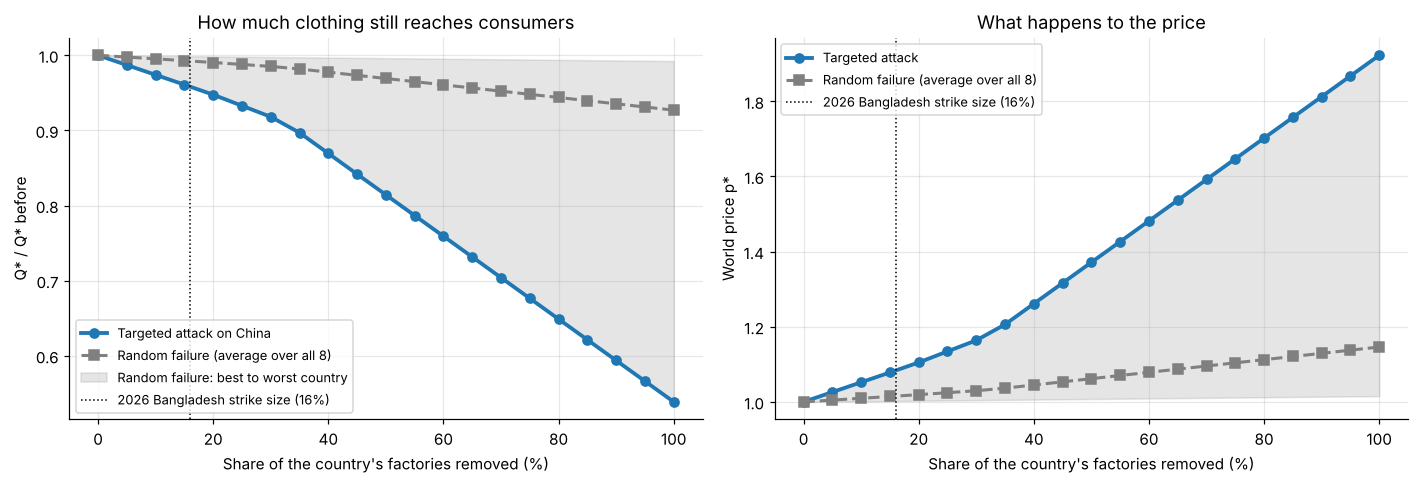

In [9]:
Q0 = MKT["P"].sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: share of clothing still traded (the percolation-style curve)
ax[0].plot(F * 100, attack.Q / Q0, "o-", color=COLORS[TARGET], lw=2.5,
           label=f"Targeted attack on {prod.loc[TARGET,'country']}")
m, lo, hi = (rand_stats[("Q", k)] / Q0 for k in ["mean", "min", "max"])
ax[0].plot(F * 100, m, "s--", color="gray", lw=2, label="Random failure (average over all 8)")
ax[0].fill_between(F * 100, lo, hi, color="gray", alpha=0.2, label="Random failure: best to worst country")
ax[0].set_xlabel("Share of the country's factories removed (%)"); ax[0].set_ylabel("Q* / Q* before")
ax[0].set_title("How much clothing still reaches consumers"); ax[0].legend()

# Right: world price
ax[1].plot(F * 100, attack.price, "o-", color=COLORS[TARGET], lw=2.5, label="Targeted attack")
m, lo, hi = (rand_stats[("price", k)] for k in ["mean", "min", "max"])
ax[1].plot(F * 100, m, "s--", color="gray", lw=2, label="Random failure (average over all 8)")
ax[1].fill_between(F * 100, lo, hi, color="gray", alpha=0.2)
ax[1].set_xlabel("Share of the country's factories removed (%)"); ax[1].set_ylabel("World price p*")
ax[1].set_title("What happens to the price"); ax[1].legend()

# Mark the real 2026 Bangladesh strike size (16%, README parameter 11)
for a in ax:
    a.axvline(16, color="black", ls=":", lw=1, label="2026 Bangladesh strike size (16%)")
    a.legend(fontsize=8.5, loc="lower left" if a is ax[0] else "upper left")
plt.tight_layout(); plt.show()

Attacking the hub costs much more than a random failure of the same size. Removing 20% of China's factories already raises the world price by about 10% and cuts trade by about 5%; removing all of them cuts trade by almost half. A random failure usually hits a small producer, so the others cover it and the price hardly moves. On average, random failure loses far less than the targeted attack; the top of the grey band is the case where the random pick happens to be China. This is the class result: robust to random failure, fragile when the hub is attacked.

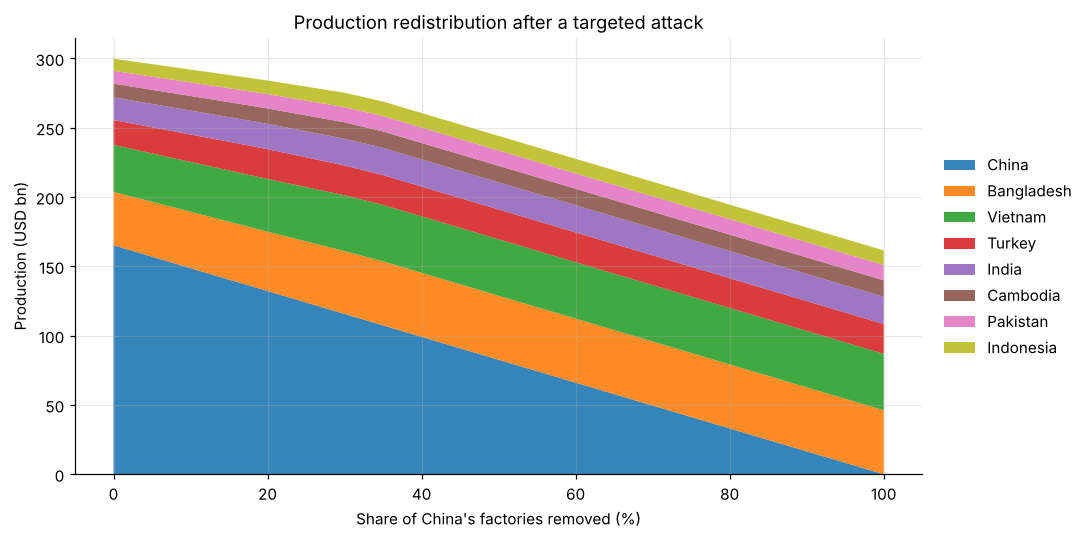

Output change of the other producers at f = 0.5 (%) -> all at their capacity limit (+20%):
Bangladesh    20.0
Vietnam       20.0
Turkey        20.0
India         20.0
Cambodia      20.0
Pakistan      20.0
Indonesia     20.0


In [10]:
# Who takes over the production? Stacked output of every producer under the targeted attack
fig, ax = plt.subplots(figsize=(10, 5))
cols = [f"P_{c}" for c in PRODUCERS]
ax.stackplot(F * 100, attack[cols].T.values, colors=[COLORS[c] for c in PRODUCERS],
             labels=[prod.loc[c, "country"] for c in PRODUCERS], alpha=0.9)
ax.set_xlabel(f"Share of {prod.loc[TARGET,'country']}'s factories removed (%)")
ax.set_ylabel("Production (USD bn)")
ax.set_title("Production redistribution after a targeted attack")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout(); plt.show()

# Gain of every other producer at f = 0.5, in % of its own baseline
row = attack.loc[np.isclose(attack.f, 0.5)].iloc[0]
gain = {prod.loc[c, "country"]: 100 * (row[f"P_{c}"] / P0[c] - 1) for c in PRODUCERS if c != TARGET}
print("Output change of the other producers at f = 0.5 (%) -> all at their capacity limit (+20%):")
print(pd.Series(gain).round(1).to_string())

In [11]:
# Real events: run each one as a shock on the country where it happened (events.csv)
real = events.dropna(subset=["attack_fraction"])
real = real[real.country.isin(PRODUCERS)]
rows = []
for _, e in real.iterrows():
    r = run_attack(MKT, e.country, float(e.attack_fraction))
    rows.append({"date": e.date, "event": e.event, "share of factories hit": f"{100*e.attack_fraction:.2f}%",
                 "world price change (%)": round(100 * (r["price"] - 1), 3),
                 "world trade change (%)": round(100 * (r["Q"] / Q0 - 1), 3)})
display(pd.DataFrame(rows))

,date,event,share of factories hit,world price change (%),world trade change (%)
0,2005-04,Spectrum garment factory collapse,0.03%,0.002,-0.001
1,2012-11-24,Tazreen Fashions fire,0.03%,0.002,-0.001
2,2013-04-24,Rana Plaza collapse,0.15%,0.011,-0.005
3,2023-10-23,Bangladesh garment wage strike,18.07%,1.297,-0.648
4,2023-07 to 2026-06,Factory closures,12.11%,0.869,-0.435
5,2026-11-01,Bangladesh garment wage strike,15.93%,1.143,-0.572


Every real Bangladesh event is small compared with the network: even the 2026 strike (16% of factories) moves the world price by only about 1%, because the other producers cover most of the lost output. That fits what happened after Rana Plaza, when Bangladesh's exports kept growing. A shock of the same size in China would matter much more.

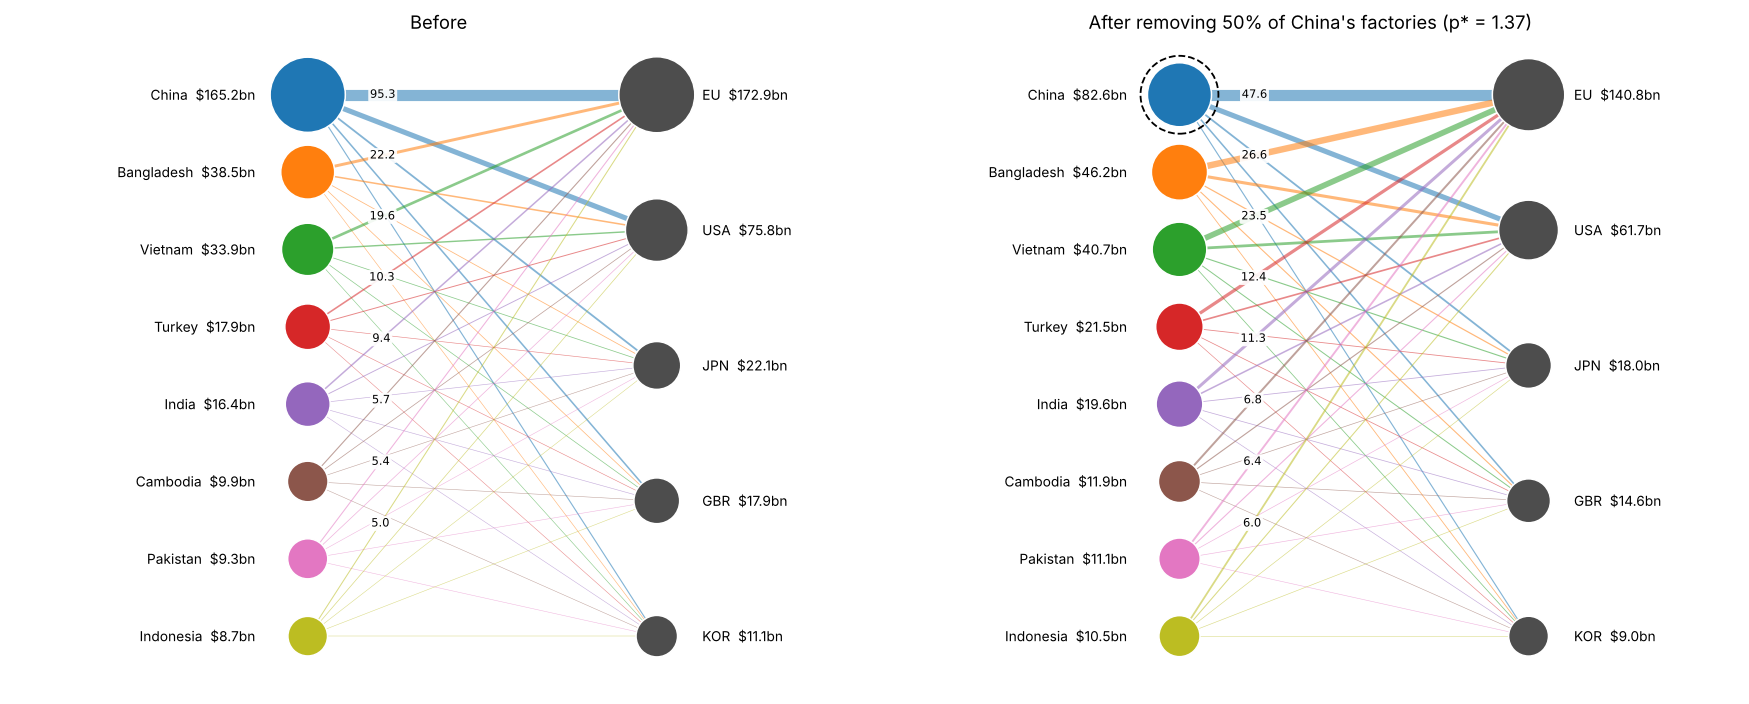

In [12]:
# The network after a 50% attack on the hub, next to the baseline
p, S, D = equilibrium(MKT, shock(MKT, TARGET, 0.5))
G_hit = build_network(dict(zip(PRODUCERS, S)), dict(zip(CONSUMERS, D)))

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
draw_network(G0, "Before", ax[0])
draw_network(G_hit, f"After removing 50% of {prod.loc[TARGET,'country']}'s factories (p* = {p:.2f})",
             ax[1], ref=G0)
plt.tight_layout(); plt.show()

---
# 6. Sensitivity: how much do the chosen parameters matter?

$\varepsilon$ (demand elasticity) and the spare capacity share have no data behind them, so we sweep them. Because all market settings live in `PARAMS`, a sweep is just a new dictionary.

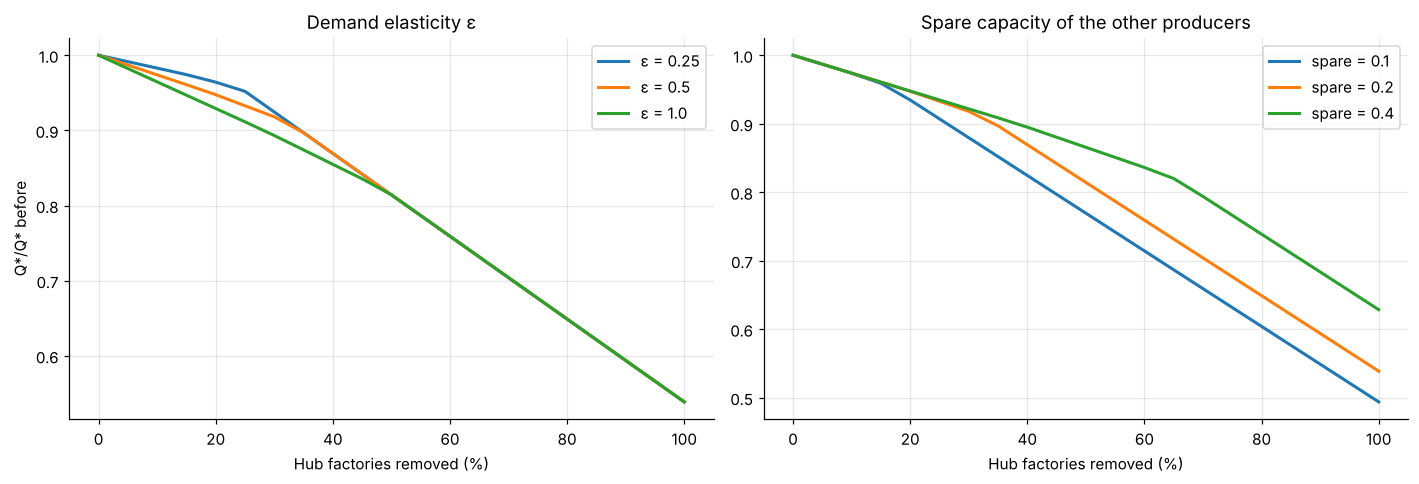

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for eps in [0.25, 0.5, 1.0]:
    m = calibrate(dict(PARAMS, eps=eps))
    q = [equilibrium(m, shock(m, TARGET, f))[1].sum() / m["P"].sum() for f in F]
    ax[0].plot(F * 100, q, lw=2, label=f"ε = {eps}")
ax[0].set_title("Demand elasticity ε"); ax[0].set_xlabel("Hub factories removed (%)"); ax[0].set_ylabel("Q*/Q* before"); ax[0].legend()

for spare in [0.1, 0.2, 0.4]:
    m = calibrate(dict(PARAMS, spare=spare))
    q = [equilibrium(m, shock(m, TARGET, f))[1].sum() / m["P"].sum() for f in F]
    ax[1].plot(F * 100, q, lw=2, label=f"spare = {spare}")
ax[1].set_title("Spare capacity of the other producers"); ax[1].set_xlabel("Hub factories removed (%)"); ax[1].legend()
plt.tight_layout(); plt.show()

More spare capacity means the other producers can replace more of China's lost output, so less trade is lost. Demand elasticity only matters for small shocks: with a higher ε consumers react more to the price, so trade drops a bit faster at first. From about 50% on the curves meet, because every other producer is already at full capacity and trade is simply limited by what is left. The main result (attacking the hub is much worse than a random failure) holds for every value we tried.

---
# 7. Next steps

- Replace `edges_estimated.csv` with real BACI flows (HS 61 + 62) and compare them with the proportional null model.
- Simulation 2 (brand ethics): Brand B only uses producers with safety score $S_i \ge T$, so it gets its own equilibrium price.
- Simulation 3 (wages): new factories by preferential attachment, wages raise $c_i$.
- Simulation 4 (pollution haven): stricter rules raise $c_i = \lambda W_i (1 + \kappa E_i/10)$.

**AI Prompts Used Throughout the Whole Assignment**

1. (add the prompts you used here, as in the Vilar notebook)